# Correlation and Stationary Time Series

## R setup

The examples use the `astsa` package and its time-series datasets and plotting utilities. Run the setup cell before subsequent code.

In [1]:
if (!requireNamespace("astsa", quietly=TRUE)) install.packages("astsa", repos="https://cloud.r-project.org")
library(astsa)
options(digits=4)


Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)



## Mean function and time dependence

**Stochastic process:** a sequence of random variables $\{x_t\}$ indexed by time $t$. A **realization** is one observed sequence from that process. **Expected value** is the theoretical average across possible realizations at a fixed time.

The **mean function** is

$$
\mu_{x,t}=E(x_t),
$$

where $x_t$ is the value at time $t$, $E(\cdot)$ is expectation, and $\mu_{x,t}$ is the process mean at that time. A constant sample average does **not** by itself establish that the theoretical mean is constant.

For independent zero-mean white noise $w_t$ and the centered three-point filter

$$
v_t=\frac{w_{t-1}+w_t+w_{t+1}}{3}, \qquad E(v_t)=0.
$$

For a **random walk with drift** $x_t=\delta+x_{t-1}+w_t$ starting from $x_0=0$,

$$
x_t=\delta t+\sum_{j=1}^{t}w_j,\qquad E(x_t)=\delta t.
$$

Here $\delta$ is the expected change per time step, so a positive drift creates a linearly rising mean, even though an individual path can move down.

For a deterministic **signal plus noise** series,

$$
x_t=2\cos\!\left(\frac{2\pi(t+15)}{50}\right)+w_t,
\qquad E(x_t)=2\cos\!\left(\frac{2\pi(t+15)}{50}\right).
$$

The cosine is the time-varying mean; zero-mean noise changes the observed trajectory, not the expected value.

Observed mean of increments with drift: 0.3823 
Specified theoretical drift: 0.3 


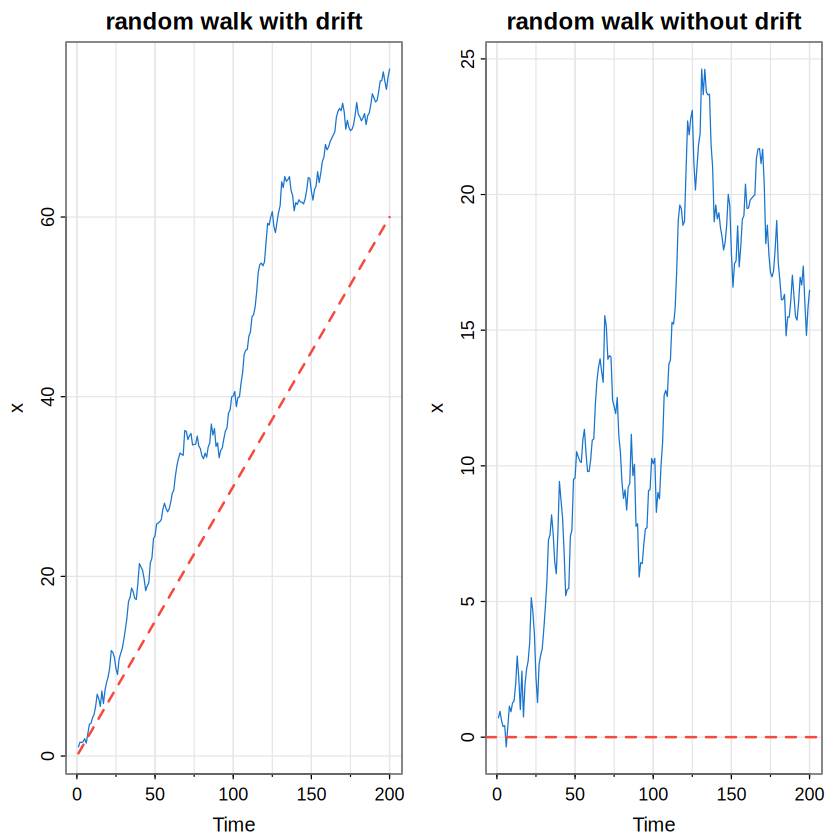

In [2]:
set.seed(314159265)
t = 1:200
w = rnorm(200)
delta = .3
x = cumsum(w)
xd = cumsum(w + delta)
par(mfrow=c(1,2))
tsplot(xd, col=4, main="random walk with drift", ylab="x")
lines(delta*t, col=2, lty=2, lwd=2)
tsplot(x, col=4, main="random walk without drift", ylab="x")
abline(h=0, col=2, lty=2, lwd=2)
cat("Observed mean of increments with drift:", mean(diff(c(0,xd))), "
")
cat("Specified theoretical drift:", delta, "
")
par(mfrow=c(1,1))

**Result interpretation:** The simulation reports a mean increment of **0.3823**, compared with the specified theoretical drift $\delta=0.3$. The difference of $0.0823$ comes from the average of the simulated random shocks; drift is the *expected* increment, not the increment observed at every step. In the left graph, the dashed line is the theoretical mean $E(x_t)=0.3t$ and the jagged line is one random-walk realization. In the right graph, the dashed zero line is the mean when $\delta=0$. Neither path has stationary variance: $\operatorname{var}(x_t)=t\sigma_w^2$ grows with time. The x-axis counts time steps and the y-axis is the accumulated series value.

## Autocovariance: dependence measured on the original scale

**Covariance** measures linear co-movement. **Autocovariance** measures covariance between observations of the *same* series at two time points:

$$
\gamma_x(s,t)=\operatorname{cov}(x_s,x_t)
=E\!\left[(x_s-\mu_s)(x_t-\mu_t)\right].
$$

Here $s$ and $t$ are time indices. At the same time point, $\gamma_x(t,t)=\operatorname{var}(x_t)$. A positive value indicates that above-mean values at one time tend to coincide with above-mean values at the other; a negative value suggests opposite departures. Zero covariance rules out a linear association, **not necessarily every form of dependence**.

For **white noise** $w_t\sim\operatorname{WN}(0,\sigma_w^2)$, observations at distinct times are uncorrelated:

$$
\operatorname{cov}(w_s,w_t)=
\begin{cases}
\sigma_w^2, & s=t,\\
0, & s\ne t.
\end{cases}
$$

$\sigma_w^2$ is the innovation variance. White noise requires zero mean, constant finite variance, and zero autocovariance at nonzero lags; it does not in general require independent or normally distributed observations.

### Covariance of linear combinations

For $U=\sum_{j=1}^{m}a_jX_j$ and $V=\sum_{k=1}^{r}b_kY_k$,

$$
\operatorname{cov}(U,V)=\sum_{j=1}^{m}\sum_{k=1}^{r}
 a_jb_k\operatorname{cov}(X_j,Y_k).
$$

$a_j,b_k$ are fixed **filter weights**. Shared innovation terms determine covariance in the white-noise moving-average examples.

For $v_t=(w_{t-1}+w_t+w_{t+1})/3$, with $\sigma_w^2=1$:

$$
\gamma_v(h)=
\begin{cases}
3/9,&h=0,\\
2/9,&|h|=1,\\
1/9,&|h|=2,\\
0,&|h|>2.
\end{cases}
$$

**Manual check:** $v_t$ and $v_{t+1}$ share two innovation terms ($w_t$ and $w_{t+1}$). Their covariance is $2(1/3)(1/3)\sigma_w^2=2\sigma_w^2/9$.

  lag theoretical_covariance sample_covariance
1   0                 0.3333          0.329545
2   1                 0.2222          0.218601
3   2                 0.1111          0.109676
4   3                 0.0000         -0.001971
5   4                 0.0000         -0.000868


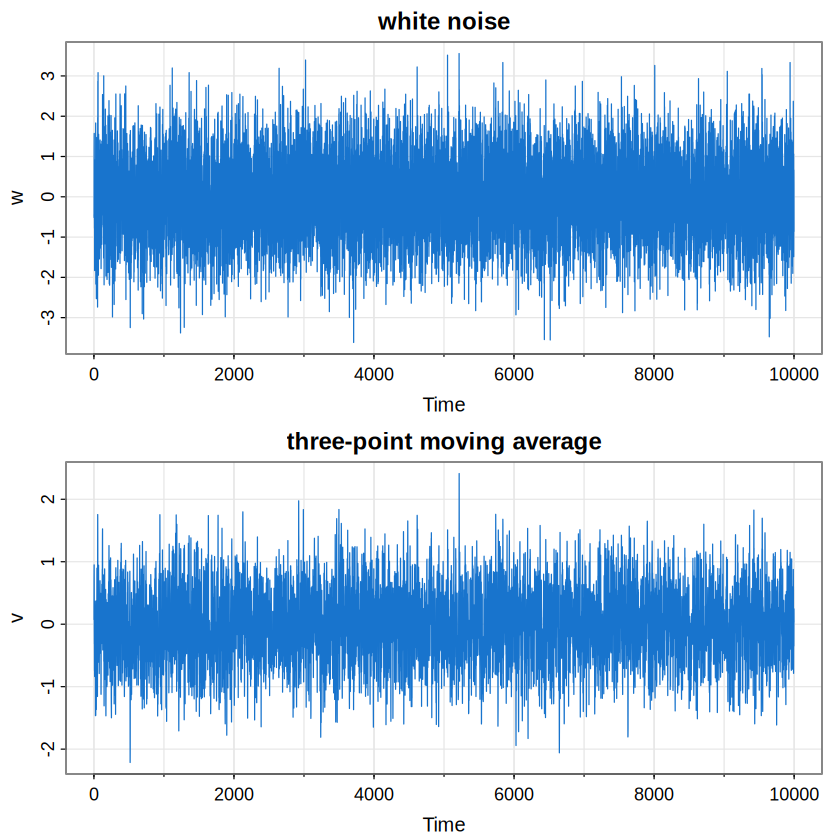

In [3]:
set.seed(90210)
w = rnorm(10000)
v = filter(w, sides=2, filter=rep(1/3,3))
v = as.numeric(na.omit(v))
lag_cov = function(z, h) {
  z = as.numeric(z)
  n = length(z)
  m = mean(z)
  sum((z[1:(n-h)]-m)*(z[(1+h):n]-m))/n
}
observed = sapply(0:4, function(h) lag_cov(v,h))
theoretical = c(3,2,1,0,0)/9
print(data.frame(lag=0:4, theoretical_covariance=theoretical,
                 sample_covariance=observed))
par(mfrow=2:1)
tsplot(w, main="white noise", col=4)
tsplot(v, main="three-point moving average", col=4)
par(mfrow=c(1,1))

**Numerical and graph interpretation:** The theoretical lag-0 through lag-4 covariances are $0.3333$, $0.2222$, $0.1111$, $0$, and $0$. Their simulated estimates are **0.329545**, **0.218601**, **0.109676**, **−0.001971**, and **−0.000868**. Lag 0 is variance. Adjacent filtered values share two innovations, values two steps apart share one, and values three or more steps apart share none. Negative estimates near zero do not imply a meaningful negative population covariance; finite simulations fluctuate around zero. In the graph, the horizontal axis is time and the vertical axis is the simulated value. Averaging makes the lower trace smoother than white noise and reduces variability.

### Why a random walk is different

With $x_t=\sum_{j=1}^{t}w_j$ and independent white noise,

$$
\operatorname{cov}(x_s,x_t)=\min(s,t)\sigma_w^2,
\qquad \operatorname{var}(x_t)=t\sigma_w^2.
$$

The two paths share innovations up to the earlier time $\min(s,t)$. For example, $x_2=w_1+w_2$ and $x_4=w_1+w_2+w_3+w_4$, so $\operatorname{cov}(x_2,x_4)=2\sigma_w^2$. Covariance depends on absolute time, not only on the separation between observations.

In [4]:
sigma2 = 1
s = c(2,20,100)
t = c(4,22,102)
print(data.frame(s=s, t=t, lag=t-s,
                 theoretical_covariance=pmin(s,t)*sigma2,
                 variance_at_t=t*sigma2))

    s   t lag theoretical_covariance variance_at_t
1   2   4   2                      2             4
2  20  22   2                     20            22
3 100 102   2                    100           102


**Interpretation:** All listed pairs are **two time steps apart**. Nevertheless, the theoretical covariances are **2**, **20**, and **100**, while the variances at the later times are **4**, **22**, and **102**. The random-walk covariance depends on the absolute time positions, not just the lag, violating weak stationarity. Its increasing variance also means a typical path may wander farther from its mean as time progresses.

## Autocorrelation and ACF

**Autocorrelation** rescales autocovariance to a unitless number between $-1$ and $1$:

$$
\rho_x(s,t)=\frac{\gamma_x(s,t)}
{\sqrt{\gamma_x(s,s)\gamma_x(t,t)}}.
$$

The **lag** $h$ is the number of time steps separating observations. For a stationary series, the **autocorrelation function (ACF)** is

$$
\rho(h)=\frac{\gamma(h)}{\gamma(0)},\qquad \rho(0)=1.
$$

A correlation near $1$ means strong positive *linear* association at that lag; near $-1$ means strong negative association; near $0$ means weak or absent linear association. Correlation alone does not prove causation or guarantee a useful forecast.

For the three-point moving average,

$$
\rho_v(h)=
\begin{cases}
1,&h=0,\\
2/3,&|h|=1,\\
1/3,&|h|=2,\\
0,&|h|>2.
\end{cases}
$$

The theoretical ACF is symmetric: $\rho(h)=\rho(-h)$.

Theoretical lag-1 ACF: 0.6667 
Theoretical lag-2 ACF: 0.3333 


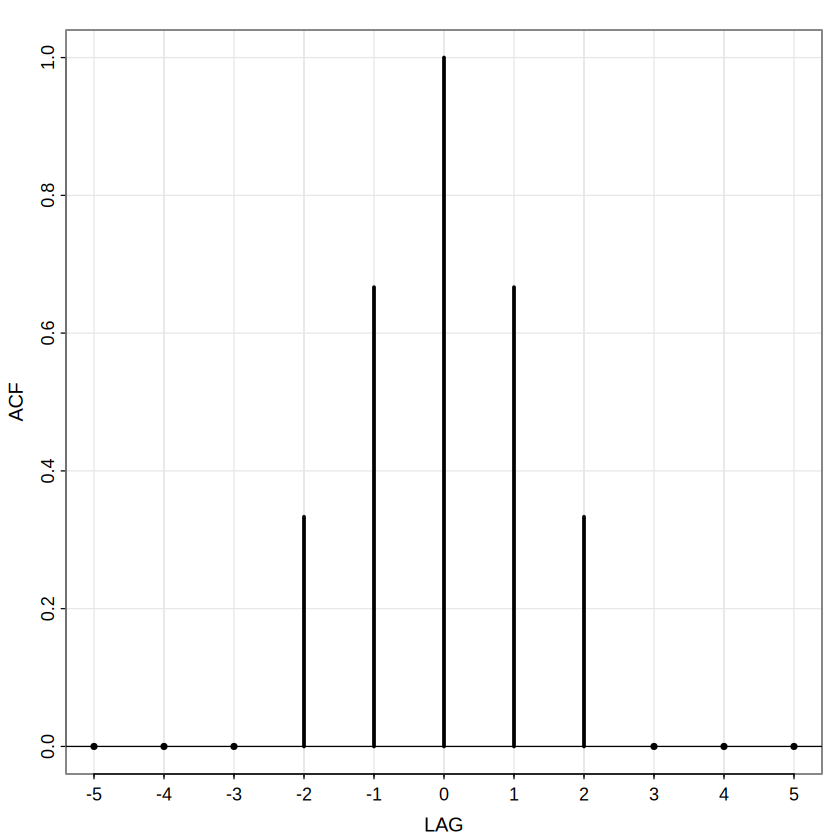

In [5]:
ACF = c(0,0,0,1,2,3,2,1,0,0,0)/3
LAG = -5:5
tsplot(LAG, ACF, type="h", lwd=3, xlab="LAG", ylab="ACF")
abline(h=0)
points(LAG[-(4:8)], ACF[-(4:8)], pch=20)
axis(1, at=seq(-5,5,by=2))
cat("Theoretical lag-1 ACF:", ACF[LAG==1], "
")
cat("Theoretical lag-2 ACF:", ACF[LAG==2], "
")

**Graph interpretation:** The horizontal axis is lag and the vertical axis is correlation. The plot is symmetric around lag zero. Lag 1 has ACF $2/3$, lag 2 has ACF $1/3$, and all larger absolute lags are zero. The abrupt cutoff after lag 2 is a distinctive feature of this finite moving-average filter. This graph is *theoretical*; it has no sampling uncertainty bands.

## Stationarity: when statistical behavior stays stable

**Weak (covariance) stationarity** means: (1) finite variance and constant mean $E(x_t)=\mu$; (2) covariance depends only on lag, $\gamma(s,t)=\gamma(t-s)$, not on calendar time. Constant variance is implied by the covariance condition at lag zero.

$$
\gamma(h)=\operatorname{cov}(x_{t+h},x_t),\quad
\gamma(0)=\operatorname{var}(x_t),\quad
\gamma(-h)=\gamma(h).
$$

**Stationary examples:** white noise; the three-point moving average of stationary white noise.

**Nonstationary examples:** random walk (growing variance); random walk with drift (changing mean and variance).

**Trend stationarity** describes a process such as

$$
x_t=\beta t+y_t,\quad E(x_t)=\beta t+\mu_y,\quad
\operatorname{cov}(x_{t+h},x_t)=\gamma_y(h),
$$

where $y_t$ is stationary. The full $x_t$ is not weakly stationary because its mean changes; removing the known deterministic trend leaves a stationary process.

Mean of detrended series: -0.03702 
Variance of detrended series: 0.9015 


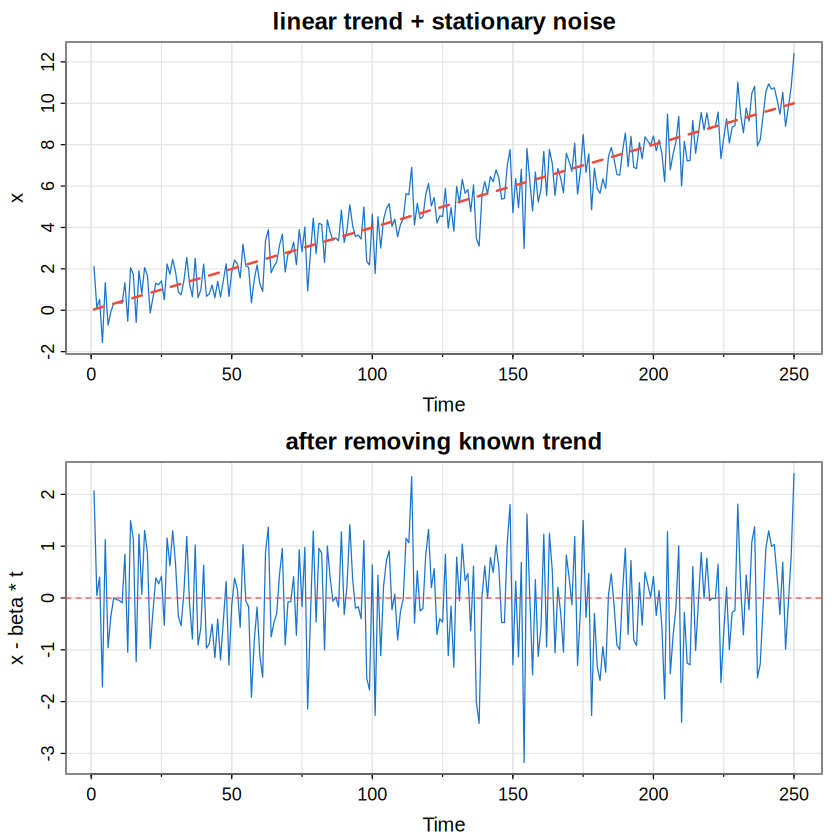

In [6]:
set.seed(205)
t = 1:250
y = rnorm(250)
beta = .04
x = beta*t + y
par(mfrow=c(2,1))
tsplot(x, col=4, main="linear trend + stationary noise")
lines(beta*t, col=2, lty=2, lwd=2)
tsplot(x-beta*t, col=4, main="after removing known trend")
abline(h=0, col=2, lty=2)
par(mfrow=c(1,1))
cat("Mean of detrended series:", mean(x-beta*t), "
")
cat("Variance of detrended series:", var(x-beta*t), "
")

**Graph and result interpretation:** The upper plot contains a deterministic rising trend $0.04t$ plus stationary random variation; the lower plot subtracts the known trend and fluctuates around zero. The detrended sample mean is **−0.03702** (the theoretical mean is $0$), and the sample variance is **0.9015** (the theoretical variance is $1$). The differences reflect finite-sample variation. Removing a correctly specified deterministic trend can recover a stationary remainder in this simulated example; detrending alone does not guarantee stationarity for real data.

### Autoregression AR(1)

**Autoregression** uses earlier values of the same series to model the current value. For an AR(1),

$$
x_t=\phi x_{t-1}+w_t,
$$

$\phi$ is the coefficient on the previous observation, and $w_t$ is a new zero-mean innovation independent of earlier values. For a causal stationary AR(1), $|\phi|<1$, and

$$
E(x_t)=0,\quad \gamma(0)=\frac{\sigma_w^2}{1-\phi^2},\quad
\gamma(h)=\phi^{|h|}\gamma(0),\quad \rho(1)=\phi.
$$

**Manual example:** if $\phi=0.6$ and $\sigma_w^2=1$, then $\operatorname{var}(x_t)=1/(1-0.6^2)=1.5625$ and $\rho(1)=0.6$. Positive $\phi$ produces persistence; negative $\phi$ tends to alternate signs. The condition $|\phi|<1$ ensures distant innovations have diminishing effects.

  lag theoretical  sample
1   0     1.00000 1.00000
2   1     0.60000 0.60593
3   2     0.36000 0.37896
4   3     0.21600 0.23229
5   4     0.12960 0.13403
6   5     0.07776 0.07501
Theoretical variance: 1.562 
Sample variance: 1.582 


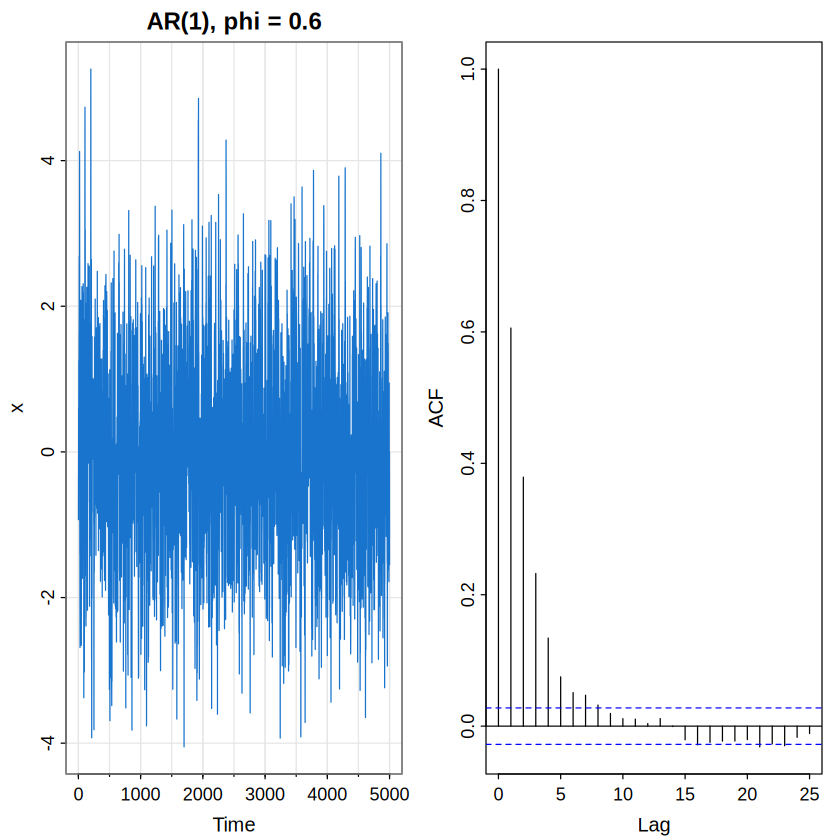

In [7]:
set.seed(220)
phi = .6
w = rnorm(5000 + 200)
x = filter(w, filter=phi, method="recursive")[-(1:200)]
a = acf(x, lag.max=5, plot=FALSE)$acf
print(data.frame(lag=0:5, theoretical=phi^(0:5),
                 sample=as.numeric(a)[1:6]))
cat("Theoretical variance:", 1/(1-phi^2), "
")
cat("Sample variance:", var(as.numeric(x)), "
")
par(mfrow=c(1,2))
tsplot(x, col=4, main="AR(1), phi = 0.6")
acf(x, lag.max=25, main="sample ACF of AR(1)")
par(mfrow=c(1,1))

**Numerical and graph interpretation:** At lags $1$–$5$, the theoretical ACF is **0.6000, 0.3600, 0.2160, 0.1296, 0.07776**; the sample ACF is **0.60593, 0.37896, 0.23229, 0.13403, 0.07501**. The sample variance **1.582** is close to the theoretical $1/(1-0.6^2)=1.5625$. In the left plot, positive $\phi=0.6$ makes successive values tend to persist rather than alternate; the right ACF plot decays toward zero as the lag grows. Minor differences from theoretical values arise from sampling. The x-axis of the left panel represents the observation index; the ACF plot's x-axis gives lag.

### Wold representation (linear filtering)

For a **purely nondeterministic, covariance-stationary** process, the Wold representation expresses observations through present and past uncorrelated innovations:

$$
x_t=\mu+\sum_{j=0}^{\infty}\psi_jw_{t-j},\qquad
\psi_0=1,\quad \sum_{j=0}^{\infty}\psi_j^2<\infty.
$$

Here $\psi_j$ is the weight on the shock $j$ periods earlier. The squared-summability condition ensures finite variance. Its autocovariance is

$$
\gamma(h)=\sigma_w^2\sum_{j=0}^{\infty}\psi_{j+h}\psi_j, \qquad h\ge 0.
$$

For a stationary AR(1), $\psi_j=\phi^j$. Hence $\gamma(h)=\sigma_w^2\phi^h/(1-\phi^2)$ for $h\ge0$. This links autoregression, filtering, and ACF calculations.

In [8]:
phi = .6
psi = phi^(0:30)
sigma2 = 1
for (h in 0:3) {
  gamma_approx = sigma2*sum(psi[(1+h):31]*psi[1:(31-h)])
  gamma_exact = sigma2*phi^h/(1-phi^2)
  cat("lag", h, ": truncated filter", round(gamma_approx,5),
      ", exact", round(gamma_exact,5), "
")
}

lag 0 : truncated filter 1.562 , exact 1.562 
lag 1 : truncated filter 0.9375 , exact 0.9375 
lag 2 : truncated filter 0.5625 , exact 0.5625 
lag 3 : truncated filter 0.3375 , exact 0.3375 


**Interpretation:** The truncated filter reproduces the stationary AR(1) theoretical covariances to the displayed precision: **1.5625** at lag $0$, **0.9375** at lag $1$, **0.5625** at lag $2$, and **0.3375** at lag $3$. The weights $\psi_j=0.6^j$ shrink geometrically, so contributions from distant past innovations become small. Agreement shows that a finite approximation closely matches the theoretical infinite filter for this parameter value; it is not a fitted-model assessment.

## Joint stationarity and cross-correlation

**Cross-covariance** concerns two different series. The processes $x_t$ and $y_t$ are **jointly stationary** when each is weakly stationary and their cross-covariance depends only on lag:

$$
\gamma_{xy}(h)=\operatorname{cov}(x_{t+h},y_t),\qquad
\rho_{xy}(h)=\frac{\gamma_{xy}(h)}{\sqrt{\gamma_x(0)\gamma_y(0)}}.
$$

The **cross-correlation function (CCF)** helps describe leading and lagging relationships. Unlike the ACF, it need not be symmetric: $\rho_{xy}(-h)$ can differ from $\rho_{xy}(h)$.

For $x_t=w_t+w_{t-1}$ and $y_t=w_t-w_{t-1}$, with white-noise variance $\sigma_w^2$:

$$
\gamma_x(0)=\gamma_y(0)=2\sigma_w^2,\qquad
\rho_{xy}(h)=
\begin{cases}
\phantom{-}1/2,&h=1,\\
-1/2,&h=-1,\\
0,&\text{otherwise}.
\end{cases}
$$

**Manual check:** $\operatorname{cov}(x_{t+1},y_t)=\operatorname{cov}(w_{t+1}+w_t,w_t-w_{t-1})=\sigma_w^2$, so the lag-1 correlation is $\sigma_w^2/(2\sigma_w^2)=1/2$.

  lag sample_ccf
1  -3 -0.0233353
2  -2 -0.0130551
3  -1 -0.4955766
4   0  0.0002317
5   1  0.4951555
6   2  0.0132990
7   3  0.0234464


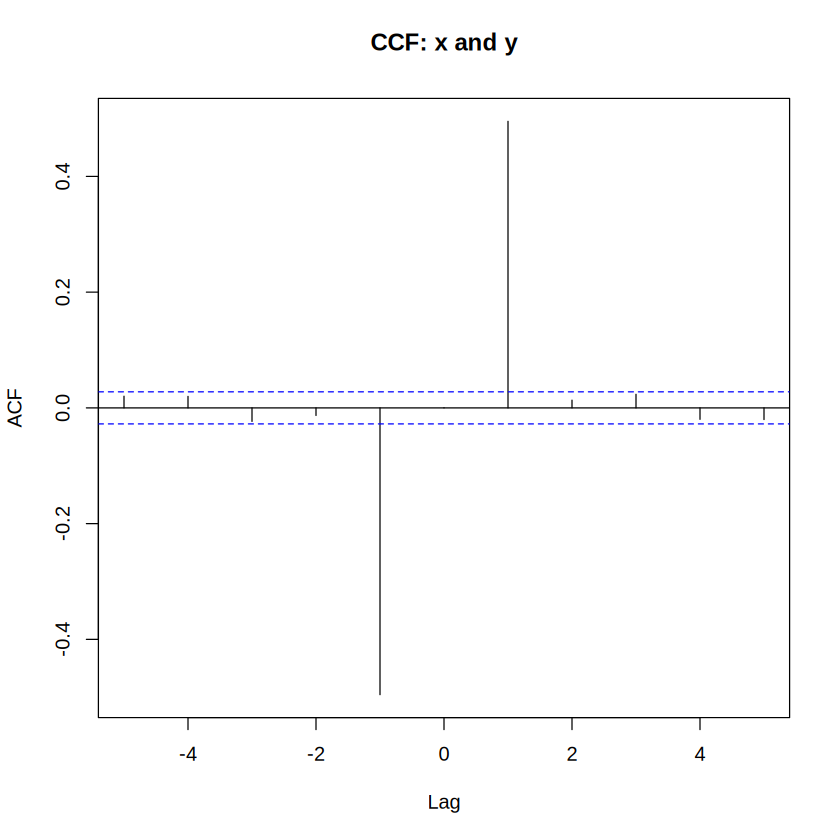

In [9]:
set.seed(240)
w = rnorm(5002)
x = ts(w[3:5002] + w[2:5001])
y = ts(w[3:5002] - w[2:5001])
ccf(x, y, lag.max=5, main="CCF: x and y")
cc = ccf(x, y, lag.max=3, plot=FALSE)
print(data.frame(lag=as.numeric(cc$lag), sample_ccf=as.numeric(cc$acf)))

**Result interpretation:** `ccf(x,y)` gives **−0.49558** at lag $-1$, **0.00023** at lag $0$, and **+0.49516** at lag $+1$. Those closely match the theoretical values $-0.5$, $0$, and $+0.5$. In the CCF graph, the horizontal axis shows lag and the vertical axis shows correlation. Zero contemporaneous correlation does *not* mean the two series are unrelated at nonzero lags. Under R's `ccf(x,y)` convention, lag $h$ corresponds to $\operatorname{corr}(x_{t+h},y_t)$; swapping the arguments reverses the lag signs.

### Delay and lead/lag interpretation

If $y_t=A x_{t-\ell}+w_t$ and $w_t$ is uncorrelated with the input $x_t$, then

$$
\gamma_{yx}(h)=A\gamma_x(h-\ell).
$$

For a delay $\ell>0$, $x_t$ **leads** $y_t$ by $\ell$ observations. The maximum covariance is expected around $h=\ell$ when plotting $\operatorname{ccf}(y,x)$. Reverse the CCF argument order and the peak changes sign. This is a convention issue, not a contradictory conclusion.

Peak covariance at lag: 5 


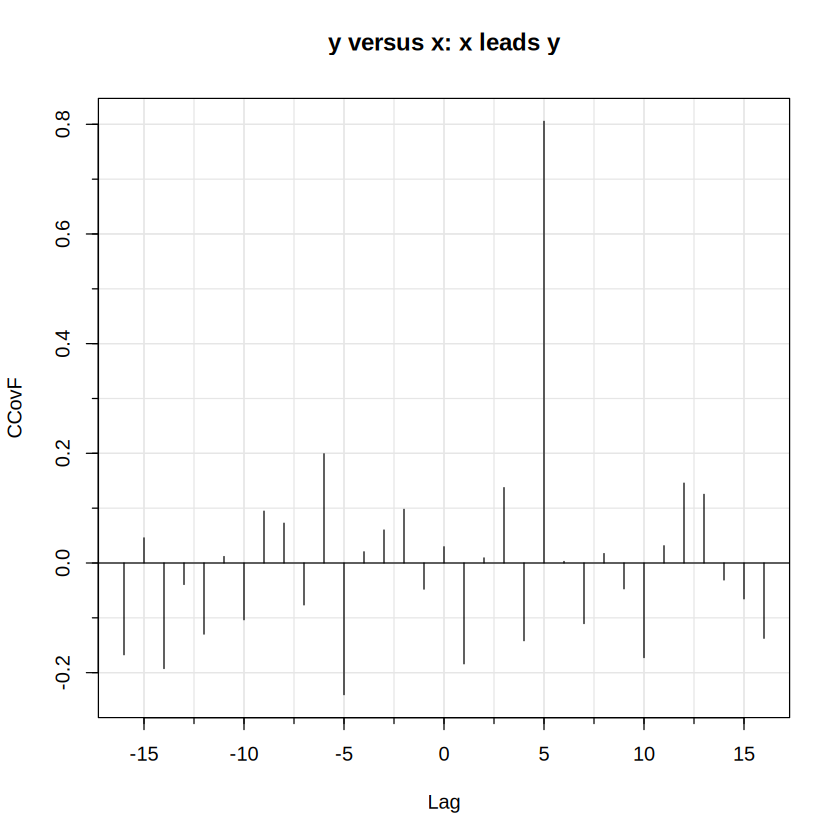

In [10]:
set.seed(250)
x = ts(rnorm(100))
y = lag(x,-5) + ts(rnorm(100))
ccf(y, x, ylab="CCovF", type="covariance", panel.first=Grid(),
    main="y versus x: x leads y")
peak = ccf(y, x, plot=FALSE, lag.max=12, type="covariance")
cat("Peak covariance at lag:", as.numeric(peak$lag)[which.max(abs(peak$acf))], "
")

**Graph and result interpretation:** The program reports the largest absolute sample cross-covariance at **lag $+5$** for `ccf(y,x)`. Under this argument order, this compares $y_{t+5}$ with $x_t$, consistent with constructing $y_t$ from $x_{t-5}$ plus noise: **$x$ leads $y$ by five observations**. The graph's horizontal axis is lag and its vertical axis is cross-covariance, which is not restricted to $[-1,1]$. Other sample covariances need not equal zero because of random noise and a finite sample. Reversing the arguments would place the corresponding peak at lag $-5$.

## Estimating mean, autocovariance, and ACF from data

With observed values $x_1,\ldots,x_n$, the **sample mean** estimates a constant stationary mean:

$$
\bar{x}=\frac{1}{n}\sum_{t=1}^{n}x_t.
$$

The **sample autocovariance** with the book's divisor $n$ and the **sample ACF** are

$$
\widehat{\gamma}(h)=\frac{1}{n}\sum_{t=1}^{n-h}
(x_{t+h}-\bar{x})(x_t-\bar{x}),\qquad
\widehat{\rho}(h)=\frac{\widehat{\gamma}(h)}{\widehat{\gamma}(0)}.
$$

For $h>0$ there are only $n-h$ matching pairs, but $\widehat\gamma(h)$ still uses divisor $n$ in this convention. **Do not confuse** the autocovariance estimate with the default sample covariance from `cov()` (which has different centering/divisor conventions).

When observations are dependent, the sample mean variance is

$$
\operatorname{var}(\bar{x})=\frac{1}{n}\sum_{h=-(n-1)}^{n-1}
\left(1-\frac{|h|}{n}\right)\gamma(h).
$$

The usual independent-sample formula $\sigma^2/n$ applies to white noise, but not automatically to correlated data.

In [11]:
z = c(1,3,2,5,4)
n = length(z)
zbar = mean(z)
gamma0 = sum((z-zbar)^2)/n
gamma1 = sum((z[2:n]-zbar)*(z[1:(n-1)]-zbar))/n
rho1 = gamma1/gamma0
cat("sample mean:", zbar, "
")
cat("sample lag-0 autocovariance:", gamma0, "
")
cat("sample lag-1 autocovariance:", gamma1, "
")
cat("sample lag-1 ACF (by hand):", rho1, "
")
cat("R acf lag-1:", as.numeric(acf(z, lag.max=1, plot=FALSE)$acf)[2], "
")

sample mean: 3 
sample lag-0 autocovariance: 2 
sample lag-1 autocovariance: 0 
sample lag-1 ACF (by hand): 0 
R acf lag-1: 0 


**Numerical interpretation:** For $z=(1,3,2,5,4)$ the computed sample mean is **3**, lag-0 autocovariance (using divisor $n=5$) is **2**, lag-1 autocovariance is **0**, and lag-1 ACF is **0**. R's `acf()` independently returns **0** at lag 1, confirming the manual formula. Zero sample lag-1 ACF means no *estimated linear correlation at this lag in these five observations*; it is not proof that the underlying process is independent or stationary.

### Approximate ACF significance bands

For a sufficiently long white-noise sequence, a sample ACF at a fixed nonzero lag is approximately $N(0,1/n)$, giving an approximate **two-standard-error band**

$$
\widehat\rho(h)\approx 0\pm\frac{2}{\sqrt n}.
$$

A bar beyond that band suggests nonzero autocorrelation at that lag *under a white-noise null model*. With many lags, some bars can exceed the band by chance. These are not universal confidence intervals for arbitrary strongly autocorrelated data.

Approximate two-SE bound: 0.1 
Sample ACF lags 1–6:
[1]  0.081 -0.083 -0.002  0.056 -0.022 -0.078


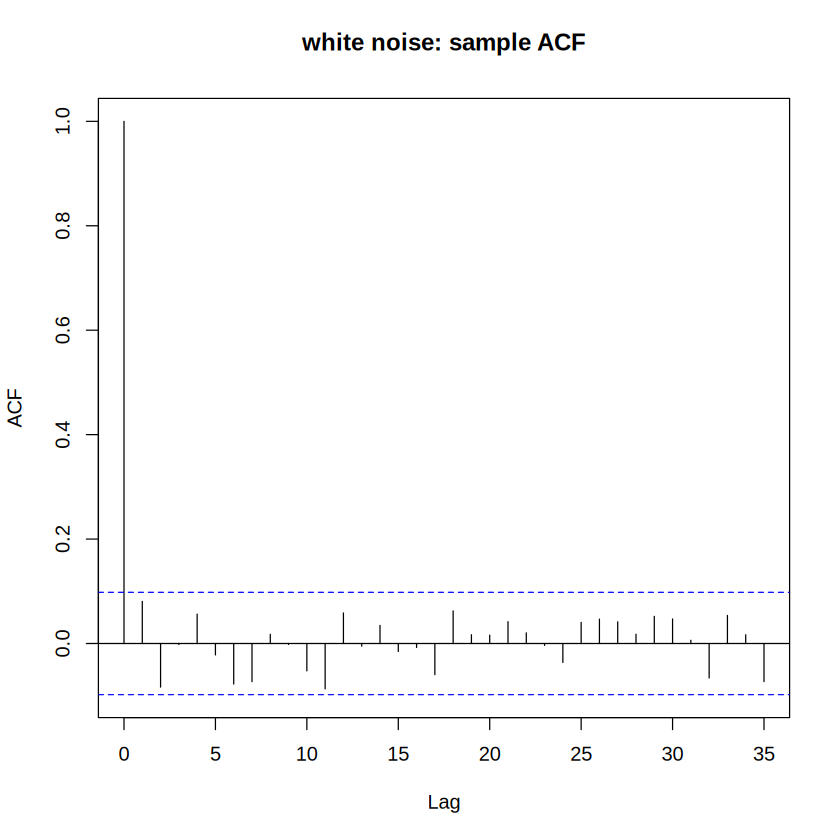

In [12]:
set.seed(270)
w = rnorm(400)
acf(w, lag.max=35, main="white noise: sample ACF")
cat("Approximate two-SE bound:", 2/sqrt(length(w)), "
")
cat("Sample ACF lags 1–6:
")
print(round(as.numeric(acf(w, lag.max=6, plot=FALSE)$acf)[-1],3))

**Graph and result interpretation:** With $n=400$, the approximate white-noise two-standard-error limits are $\pm 2/\sqrt{400}=\pm0.10$. The printed sample ACF at lags 1–6 is **0.081, −0.083, −0.002, 0.056, −0.022, −0.078**: all fall inside these limits. In the graph, lag is on the horizontal axis and the estimated autocorrelation is on the vertical axis. The lag-0 spike equals 1 by definition and is excluded from this check. Several tested lags can cross such bands by chance, so the bands are rough *individual-lag* reference limits under a white-noise null, not a conclusive test of whiteness or general confidence bounds for correlated series.

## SOI: sample ACF and lagged scatterplots

A **lagged scatterplot** places $x_{t-h}$ on the horizontal axis and $x_t$ on the vertical axis. A rising cloud suggests positive correlation; a descending cloud suggests negative correlation. The **Southern Oscillation Index (SOI)** provides monthly observations for studying dependence at short and seasonal lags.

[1]  0.60410  0.37380  0.21412  0.05014 -0.10704 -0.18699

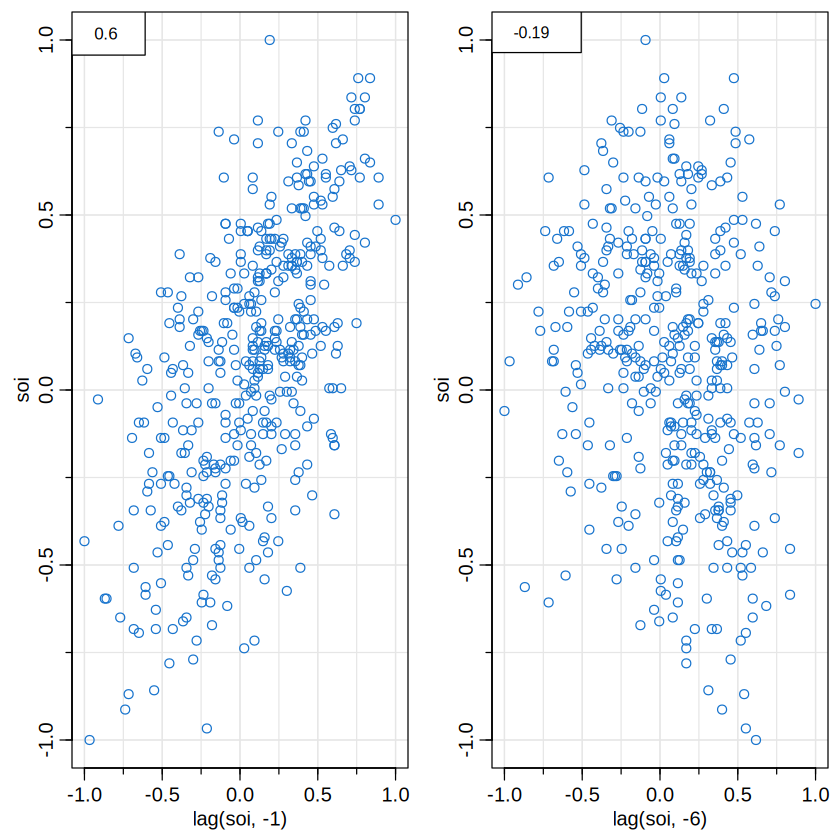

In [13]:
(r = acf1(soi, 6, plot=FALSE))
par(mfrow=c(1,2), mar=c(2.5,2.5,0,0)+.5, mgp=c(1.6,.6,0))
plot(lag(soi,-1), soi, col="dodgerblue3", panel.first=Grid())
legend("topleft", legend=round(r[1],2), bg="white", adj=.45, cex=.85)
plot(lag(soi,-6), soi, col="dodgerblue3", panel.first=Grid())
legend("topleft", legend=round(r[6],2), bg="white", adj=.25, cex=.8)
par(mfrow=c(1,1))

**Scatterplot interpretation:** The dataset's lag-1 SOI autocorrelation is approximately **+0.60**, so the one-month scatterplot has a pronounced upward tendency: higher values in one month are associated with higher values the next month. The lag-6 correlation is approximately **−0.19**, giving a weaker downward tendency for observations six months apart. In each graph the horizontal axis is the earlier SOI value and the vertical axis is the later SOI value. These are linear associations, not evidence of a causal mechanism; the rounded values reflect the dataset and estimation method.

## Sample size and theoretical ACF: a filtered coin-toss series

Let $x_t$ take $-2$ or $2$ with equal probability, independently over time. Define

$$
y_t=5+x_t-0.5x_{t-1}.
$$

The constant $5$ sets the level but does not affect covariance. Since $\operatorname{var}(x_t)=4$,

$$
\gamma_y(0)=(1+0.5^2)\cdot4=5,
\quad \gamma_y(1)=(-0.5)\cdot4=-2,
\quad \rho_y(1)=-\frac{2}{5}=-0.4,
$$

and $\rho_y(h)=0$ for $|h|>1$. The lag-1 correlation is negative because the same random input appears with opposite signs in neighboring filtered observations.

  lag theoretical sample_n10 sample_n100
1   0         1.0      1.000       1.000
2   1        -0.4     -0.223      -0.435
3   2         0.0     -0.623       0.043
4   3         0.0      0.219       0.061
5   4         0.0      0.416      -0.075
Two-SE bounds: n=10: 0.632 ; n=100: 0.2 


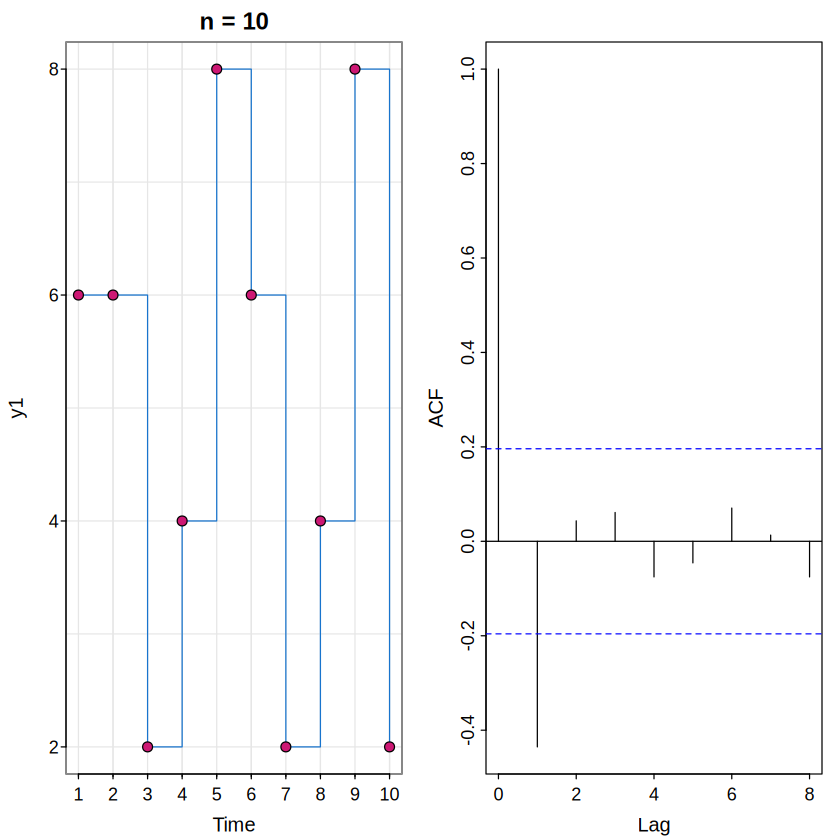

In [14]:
set.seed(101011)
x1 = sample(c(-2,2), 11, replace=TRUE)
x2 = sample(c(-2,2), 101, replace=TRUE)
y1 = 5 + filter(x1, sides=1, filter=c(1,-.5))[-1]
y2 = 5 + filter(x2, sides=1, filter=c(1,-.5))[-1]
par(mfrow=c(1,2))
tsplot(y1, type="s", col=4, xaxt="n", yaxt="n", main="n = 10")
axis(1, 1:10); axis(2, seq(2,8,2), las=1)
points(y1, pch=21, cex=1.1, bg=6)
acf(y2, lag.max=8, main="n = 100 sample ACF")
par(mfrow=c(1,1))
a1 = as.numeric(acf(y1, lag.max=4, plot=FALSE)$acf)
a2 = as.numeric(acf(y2, lag.max=4, plot=FALSE)$acf)
print(data.frame(lag=0:4, theoretical=c(1,-.4,0,0,0),
                 sample_n10=round(a1,3), sample_n100=round(a2,3)))
cat("Two-SE bounds: n=10:", round(2/sqrt(10),3),
    "; n=100:", round(2/sqrt(100),3), "
")

**Numerical and graph interpretation:** The theoretical ACF is **−0.4** at lag 1 and **0** beyond lag 1. For $n=10$, the calculated lag-1 value is **−0.223**, and the sample lag-2 and lag-4 values are **−0.623** and **0.416**, even though both have theoretical value zero. For $n=100$, the lag-1 estimate is **−0.435** and the lag-2 and lag-4 estimates are **0.043** and **−0.075**: this particular longer sample is closer to the population pattern. The left step graph shows the ten filtered outcomes over observation index; the right plot shows the longer sample's ACF over lag. The printed $2/\sqrt n$ values (**0.632** and **0.200**) are *white-noise benchmarks*, **not valid general confidence bounds for this correlated moving-average process**. A larger sample tends to yield more stable ACF estimates, but not every individual estimate must improve.

## Cross-correlation estimates and SOI–Recruitment analysis

For two jointly stationary series, the **sample cross-covariance** at nonnegative lag $h$ is

$$
\widehat{\gamma}_{xy}(h)=\frac{1}{n}\sum_{t=1}^{n-h}
(x_{t+h}-\bar{x})(y_t-\bar{y}),
\qquad
\widehat{\rho}_{xy}(h)=\frac{\widehat\gamma_{xy}(h)}
{\sqrt{\widehat\gamma_x(0)\widehat\gamma_y(0)}}.
$$

For negative lags, $\widehat\gamma_{xy}(-h)=\widehat\gamma_{yx}(h)$. A CCF peak can indicate a useful lead/lag association, but **shared cycles or trends can create apparently important peaks even when series are independent**.

In `ccf2(soi,rec)`, negative lags indicate that SOI precedes Recruitment, following the displayed `ccf(soi,rec)` convention.

[1]  0.60  0.37  0.21  0.05 -0.11 -0.19 -0.18 -0.10  0.05  0.22  0.36  0.41
[13]  0.31  0.10 -0.06 -0.17 -0.29 -0.37 -0.32 -0.19 -0.04  0.15  0.31  0.35
[25]  0.25  0.10 -0.03 -0.16 -0.28 -0.37 -0.32 -0.16 -0.02  0.17  0.33  0.39
[37]  0.30  0.16  0.00 -0.13 -0.24 -0.27 -0.25 -0.13  0.06  0.21  0.38  0.40

[1]  0.92  0.78  0.63  0.48  0.36  0.26  0.18  0.13  0.09  0.07  0.06  0.02
[13] -0.04 -0.12 -0.19 -0.24 -0.27 -0.27 -0.24 -0.19 -0.11 -0.03  0.03  0.06
[25]  0.06  0.02 -0.02 -0.06 -0.09 -0.12 -0.13 -0.11 -0.05  0.02  0.08  0.12
[37]  0.10  0.06  0.01 -0.02 -0.03 -0.03 -0.02  0.01  0.06  0.12  0.17  0.20

  lag_months      ccf
1        -12 -0.17545
2         -6 -0.59870
3          0  0.02495
4          6 -0.23151
5         12  0.16153


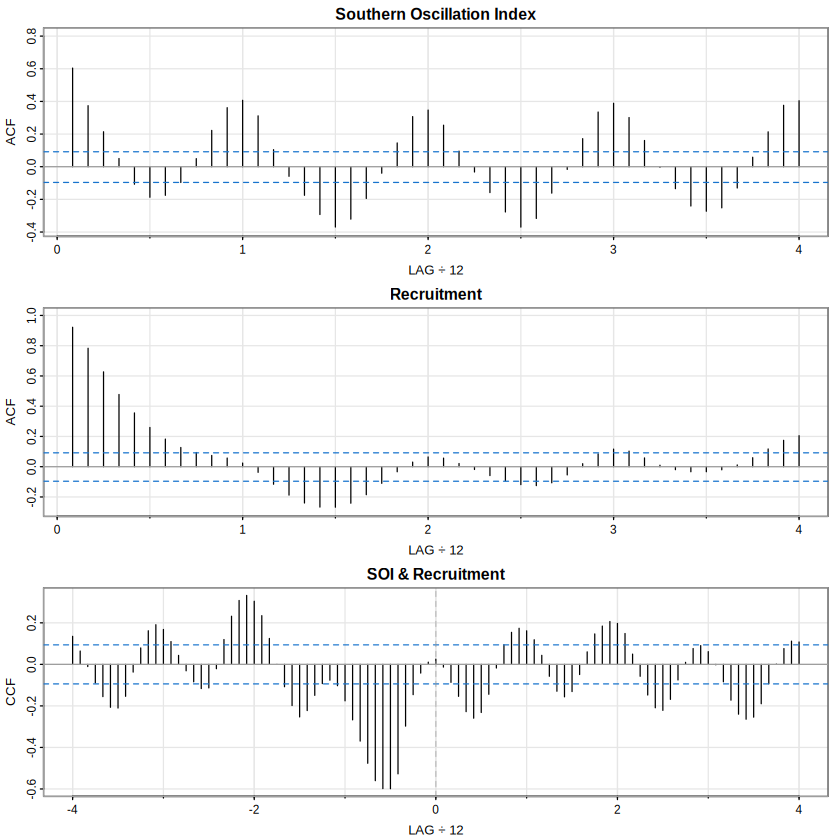

In [15]:
par(mfrow=c(3,1))
acf1(soi, 48, main="Southern Oscillation Index")
acf1(rec, 48, main="Recruitment")
ccf2(soi, rec, 48, main="SOI & Recruitment")
par(mfrow=c(1,1))
# Numeric CCF values at selected monthly lags
soi_rec_ccf = ccf(soi, rec, lag.max=12, plot=FALSE)
selected_lags = c(-12,-6,0,6,12)
print(data.frame(lag_months=selected_lags,
                 ccf=sapply(selected_lags, function(h)
                   as.numeric(soi_rec_ccf$acf)[which(round(as.numeric(soi_rec_ccf$lag)*frequency(soi))==h)[1]])))

**Graph and numerical interpretation:** The SOI and Recruitment ACF panels display positive correlations near annual (12-month) multiples and negative correlations near half-year separations, indicating recurring seasonal dependence. The CCF table reports **−0.17545** at lag $-12$ months, **−0.59870** at **$-6$ months**, **+0.02495** at lag 0, **−0.23151** at $+6$ months, and **+0.16153** at $+12$ months. For `ccf(soi,rec)`, lag $-6$ correlates $\mathrm{SOI}_{t-6}$ with $\mathrm{Recruitment}_t$; the negative value means higher earlier SOI is associated with lower Recruitment six months later. The **negative-lag sign indicates SOI leads Recruitment**, not vice versa. Since both are monthly `ts` series, an axis lag of $-0.5$ years means $-6$ months. The ordinary white-noise reference bands do not give valid formal significance tests for this autocorrelated CCF; seasonal association does not prove causality.

## Prewhitening: checking whether apparent CCF peaks are genuine

**Prewhitening** means removing predictable autocorrelation or shared structure before evaluating cross-correlation. The aim is to reduce misleading peaks caused by strongly structured series.

Consider two *independent* series with similar seasonal signals:

$$
X_t=2\cos\!\left(\frac{2\pi t}{12}\right)+w_{1t},\qquad
Y_t=2\cos\!\left(\frac{2\pi(t+5)}{12}\right)+w_{2t},
$$

where $w_{1t}$ and $w_{2t}$ are independent standard normal innovations. Similar seasonal patterns may yield large raw CCF spikes despite the independent noise components.

A harmonic regression estimates the periodic part of $Y_t$:

$$
Y_t=a+b\cos\!\left(\frac{2\pi t}{12}\right)
+c\sin\!\left(\frac{2\pi t}{12}\right)+\varepsilon_t.
$$

**Residuals** $\widetilde{Y}_t=Y_t-\widehat{Y}_t$ subtract the fitted signal. Both sine and cosine terms are required to represent an unknown phase shift. This is the book's simple illustration, not the general model-based prewhitening procedure for arbitrary time series.

[1]  0.51  0.32 -0.03 -0.31 -0.58 -0.59 -0.52 -0.25  0.02  0.36  0.46  0.64
[13]  0.51  0.26 -0.09 -0.30 -0.53 -0.58 -0.45 -0.21  0.03  0.36  0.47  0.53
[25]  0.40  0.25 -0.10 -0.30 -0.53 -0.53 -0.41 -0.15  0.07  0.30  0.46  0.51
[37]  0.31  0.16 -0.11 -0.31 -0.44 -0.42 -0.36 -0.13  0.12  0.30  0.37  0.41

[1]  0.53  0.33 -0.01 -0.31 -0.47 -0.62 -0.50 -0.34  0.03  0.38  0.53  0.54
[13]  0.46  0.25 -0.02 -0.28 -0.51 -0.58 -0.50 -0.27 -0.02  0.28  0.37  0.49
[25]  0.41  0.22  0.03 -0.30 -0.48 -0.52 -0.39 -0.23 -0.02  0.24  0.41  0.48
[37]  0.42  0.26 -0.01 -0.18 -0.31 -0.43 -0.38 -0.19 -0.01  0.23  0.34  0.40

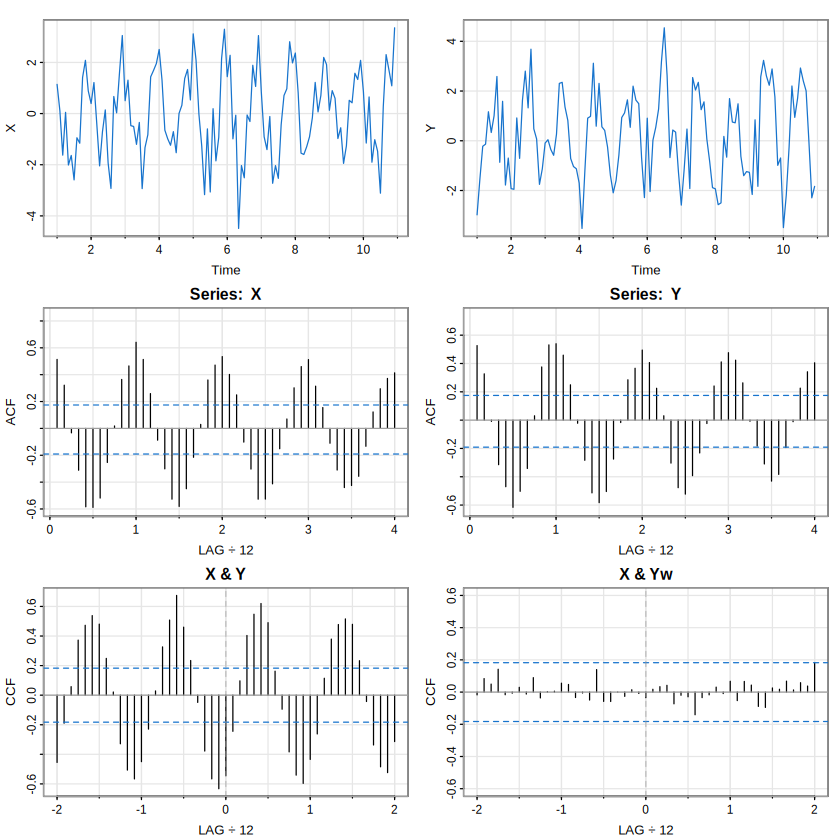

In [16]:
set.seed(1492)
num = 120
t = 1:num
X = ts(2*cos(2*pi*t/12) + rnorm(num), freq=12)
Y = ts(2*cos(2*pi*(t+5)/12) + rnorm(num), freq=12)
Yw = resid(lm(Y ~ cos(2*pi*t/12) + sin(2*pi*t/12), na.action=NULL))
par(mfrow=c(3,2))
tsplot(X, col=4); tsplot(Y, col=4)
acf1(X, 48); acf1(Y, 48)
ccf2(X, Y, 24); ccf2(X, Yw, 24, ylim=c(-.6,.6))
par(mfrow=c(1,1))

In [17]:
cat("Raw Y variance:", var(as.numeric(Y)), "
")
cat("Residual Y variance:", var(as.numeric(Yw)), "
")
cat("Lag-12 ACF of raw Y:", acf(Y, lag.max=12, plot=FALSE)$acf[13], "
")
cat("Lag-12 ACF of residual Y:", acf(Yw, lag.max=12, plot=FALSE)$acf[13], "
")
raw_ccf = as.numeric(ccf(X,Y, lag.max=12, plot=FALSE)$acf)
resid_ccf = as.numeric(ccf(X,Yw, lag.max=12, plot=FALSE)$acf)
cat("Largest absolute raw CCF (lags -12 through 12):", max(abs(raw_ccf)), "
")
cat("Largest absolute residual CCF (same lags):", max(abs(resid_ccf)), "
")

Raw Y variance: 3.002 
Residual Y variance: 1.01 
Lag-12 ACF of raw Y: 0.5393 
Lag-12 ACF of residual Y: -0.1398 
Largest absolute raw CCF (lags -12 through 12): 0.6743 
Largest absolute residual CCF (same lags): 0.1406 


**Graphs and numerical interpretation:** The two simulated series have different-phase but fixed seasonal mean waves, with independent random innovations. Their time plots and ACF panels show strong recurring annual cycles; consequently the raw CCF has repeated large seasonal correlations even though the *random innovations* are independent. Before filtering, `Y` has sample variance **3.002**, lag-12 ACF **0.5393**, and the largest absolute raw CCF over lags $-12$ to $12$ is **0.6743**. After fitting and subtracting the sinusoid from `Y`, the residual variance becomes **1.010**, its lag-12 ACF becomes **−0.1398**, and the largest absolute CCF with `X` over the same lags decreases to **0.1406**. The residual value at lag 12 is not exactly zero because the sample is finite. This illustrates how shared deterministic cycles can produce misleading raw CCF peaks. **Limitation:** This is a controlled harmonic-regression illustration. General time-series prewhitening ordinarily fits an appropriate model to the input and applies the same filter to both series before interpreting the CCF. A reduced CCF is not proof of independence.

## Reference

Shumway, R. H., & Stoffer, D. S. (2019). *Time Series: A Data Analysis Approach Using R*. Chapman & Hall/CRC Press.